## Initial analysis for language detection 

In [2]:
import os

import pandas as pd
import pyarrow.parquet as pq

from crypto_analysis.pre_processing import (
    clean_text_lang_detection,
    extract_date,
    get_lang_confidence,
)

### Load data from datalake

In [3]:
data = []

token_metadata_path = "../../../datalake/pumpfun/data/parquet/token_metadata"
for file in os.listdir(token_metadata_path):
    table = pq.read_table(os.path.join(token_metadata_path, file))
    df = table.to_pandas()

    date = extract_date(file)
    df["date"] = date
    data.append(df)

final_df = pd.concat(data, ignore_index=True)
print("Initial size: ", final_df.shape)

Initial size:  (6569510, 23)


In [2]:
final_df_n_d = final_df.dropna(subset=["meta_name", "description"])
print("Size after dropping rows with null meta_name or description: ", final_df_n_d.shape)

Size after dropping rows with null meta_name or description:  (4576292, 23)


In [4]:
final_df_n_d = final_df.dropna(subset=["meta_name", "description"])
print("Size after dropping rows with null meta_name or description: ", final_df_n_d.shape)

Size after dropping rows with null meta_name or description:  (4576292, 23)


In [3]:
final_df_n_d.reset_index(drop=True, inplace=True)

### Language Detection

In [ ]:
import fasttext

model = fasttext.load_model("../models/lid.176.bin")

In [5]:
df = final_df_n_d.copy()

In [6]:
df.shape

(4576292, 23)

In [8]:
df["meta_name"] = df["meta_name"].astype(str).apply(lambda x: x.strip())
df["description"] = df["description"].astype(str).apply(lambda x: x.strip())
df["meta_name_description"] = df["meta_name"] + " " + df["description"]

In [10]:
df["lang_confidence_is_english"] = df["meta_name_description"].apply(lambda x: get_lang_confidence(clean_text_lang_detection(x), model, threshold=0.8))
df["is_english"] = df["lang_confidence_is_english"].apply(lambda x: x[2] if x is not None else False)

In [11]:
df.shape

(4576292, 26)

In [12]:
df[df["is_english"] == False].shape

(104651, 26)

In [2]:
data_lang_detected = pq.read_table("../data/data_with_lang_detection.parquet").to_pandas()

In [ ]:
data_for_plot = data_lang_detected.copy()
data_for_plot["month"] = data_for_plot["date"].apply(lambda x: x.strftime("%Y-%m"))
data_for_plot_g = data_for_plot.groupby(["month", "is_english"]).size().reset_index(name="count")
data_for_plot_g["total_count"] = data_for_plot_g.groupby("month")["count"].transform("sum")

Plotting english tokens and non_english tokens over time

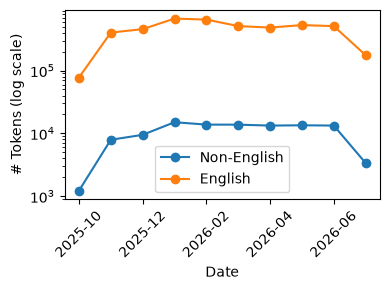

In [ ]:
import matplotlib.pyplot as plt

plot_data = (
    data_for_plot_g
    .pivot(index="month", columns="is_english", values="count")
    .rename(columns={
        True: "English",
        False: "Non-English"
    })
    .fillna(0)
    .sort_index()
)

ax = plot_data.plot(
    kind="line",
    marker="o",
    figsize=(4, 3)
)

ax.set_yscale("log")
ax.set_xlabel("Date")
ax.set_ylabel("# Tokens (log scale)")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../reports/figures/english_non_english_tokens_over_time.pdf")
plt.show()